Identifikasi dataset:

Jenis Klasifikasi: Multilabel Classification, perlu diperiksa berdasarkan kolom target.
- Independent Variables: Atribut atau fitur yang tersedia dalam dataset.
- Dependent Variables: Beberapa kolom label yang menjadi target klasifikasi.
- Jumlah Independent Variables: Sesuai jumlah kolom fitur.
- Jumlah Dependent Variables: Sesuai jumlah kolom target.
- Karakteristik Label: Satu data dapat mempunyai beberapa label aktif sekaligus.
- Tujuan: Memprediksi beberapa label yang sesuai berdasarkan karakteristik setiap data.

Penjelasan variabel:

1. Independent Variables: Digunakan sebagai informasi masukan untuk proses klasifikasi.
2. Dependent Variables: Digunakan sebagai label keluaran yang ingin diprediksi.
3. Label Biner: Jika menggunakan format 0 dan 1, angka 1 menunjukkan label aktif dan angka 0 menunjukkan label tidak aktif.

In [56]:
import glob
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

In [57]:
# Cari file otomatis; ganti manual jika perlu, contoh: DATA_PATH = "text_ua.csv"
candidates = glob.glob("water_problem_nlp_en*.csv")
DATA_PATH = candidates[0] if candidates else "dataset.csv"
print("File yang dipakai:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("IDENTIFIKASI MULTILABEL DATASET")

File yang dipakai: water_problem_nlp_en_for_Kaggle_100.csv
IDENTIFIKASI MULTILABEL DATASET


In [58]:
print("Informasi Dataset:")
df.info()

print("\nJumlah Baris dan Kolom:")
print(df.shape)

print("\nNama Kolom:")
print(df.columns.tolist())

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 1 columns):
 #   Column                                                       Non-Null Count  Dtype
---  ------                                                       --------------  -----
 0   text;env_problems;pollution;treatment;climate;biomonitoring  100 non-null    str  
dtypes: str(1)
memory usage: 932.0 bytes

Jumlah Baris dan Kolom:
(100, 1)

Nama Kolom:
['text;env_problems;pollution;treatment;climate;biomonitoring']


In [59]:
print("Lima Data Pertama:")
display(df.head())

print("\nJumlah Data Kosong:")
display(df.isnull().sum().to_frame("jumlah_kosong"))

Lima Data Pertama:


,text;env_problems;pollution;treatment;climate;biomonitoring
0,In the Southern Bug basin wastewater is discha...
1,This amount is distributed as follows: urban a...
2,Despite the similar volumes of discharged wast...
3,They bring 84% of organic pollution 86% of pho...
4,The input of the industry is between 7–21% and...



Jumlah Data Kosong:


,jumlah_kosong
text;env_problems;pollution;treatment;climate;biomonitoring,0


In [60]:
for col in df.columns:
    print("\nKolom:", col)
    print("Tipe Data:", df[col].dtype)
    print("Jumlah Nilai Unik:", df[col].nunique())
    print("Nilai Unik (maks 10):")
    print(df[col].unique()[:10])


Kolom: text;env_problems;pollution;treatment;climate;biomonitoring
Tipe Data: str
Jumlah Nilai Unik: 100
Nilai Unik (maks 10):
<StringArray>
[                                                                                                                                                                                                             'In the Southern Bug basin wastewater is discharged from 341 organized sources (Map 5). In 2011 (reference year) 211 mln. m3 was discharged in total.;1;1;;;',
                                                                                             'This amount is distributed as follows: urban and rural housing wastewater treatment facilities (WWTPs - vodocanals) – 70 mln. m3 (57 users) industry – 50 mln. m3 (79 users) agriculture – 90 mln. m3 (193 users) other users – 1 mln. m3 (12 users) (Picture. 2.1). ;1;1;;;',
                                                                                                                                

In [61]:
# Kandidat kolom label biner
binary_columns = []
for col in df.columns:
    unique_values = set(df[col].dropna().unique())
    if len(unique_values) > 0 and unique_values.issubset({0, 1, 0.0, 1.0, True, False}):
        binary_columns.append(col)

print("Kandidat Kolom Label Biner:")
print(binary_columns)
print("\nJumlah Kandidat Kolom Label:", len(binary_columns))

# Kolom teks: kolom bertipe object dengan rata-rata panjang terbesar
object_cols = [c for c in df.columns if df[c].dtype == "object"]
if object_cols:
    TEXT_COL = max(object_cols, key=lambda c: df[c].dropna().astype(str).str.len().mean())
else:
    TEXT_COL = None
print("\nKolom teks terdeteksi:", TEXT_COL)

LABEL_COLS = binary_columns
# Jika ada kolom id yang ikut terdeteksi sebagai biner, hapus manual di sini:
# LABEL_COLS = [c for c in LABEL_COLS if c not in ["id"]]

Kandidat Kolom Label Biner:
[]

Jumlah Kandidat Kolom Label: 0

Kolom teks terdeteksi: None


In [62]:
print("Jumlah data duplikat (baris penuh):", df.duplicated().sum())
if TEXT_COL:
    print("Jumlah teks duplikat:", df[TEXT_COL].duplicated().sum())
    print("Jumlah teks kosong/spasi saja:", (df[TEXT_COL].fillna("").str.strip() == "").sum())

# Visualisasi missing value
missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing):
    missing.sort_values().plot(kind="barh", figsize=(8, 4), color="tomato", title="Missing Value per Kolom")
    plt.show()
else:
    print("Tidak ada missing value.")

Jumlah data duplikat (baris penuh): 0
Tidak ada missing value.


,jumlah,persen


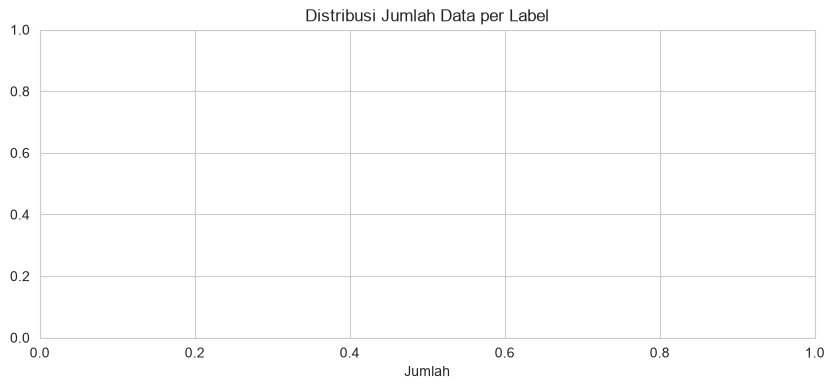

Rasio ketidakseimbangan (label terbanyak / tersedikit): nan


In [63]:
label_df = df[LABEL_COLS].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)

label_counts = label_df.sum().sort_values(ascending=False)
label_pct = (label_counts / len(df) * 100).round(2)
display(pd.DataFrame({"jumlah": label_counts, "persen": label_pct}))

plt.figure(figsize=(10, max(4, len(LABEL_COLS) * 0.35)))
sns.barplot(x=label_counts.values, y=label_counts.index, color="steelblue")
plt.title("Distribusi Jumlah Data per Label")
plt.xlabel("Jumlah")
plt.show()

print("Rasio ketidakseimbangan (label terbanyak / tersedikit):",
      round(label_counts.max() / max(label_counts.min(), 1), 2))

rare = label_counts[label_counts < 10]
if len(rare):
    print("\n[PERINGATAN] Label dengan kurang dari 10 sampel:")
    print(rare)

In [64]:
print("LABEL_COLS:", LABEL_COLS)
print("Jumlah label:", len(LABEL_COLS))

if len(LABEL_COLS) == 0:
    print("\n[STOP] LABEL_COLS kosong, heatmap tidak bisa dibuat. Cek Cell 6 dan Cell 2.")
else:
    label_df = df[LABEL_COLS].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)

    labels_per_row = label_df.sum(axis=1)
    print("\nStatistik jumlah label per sampel:")
    print(labels_per_row.describe())
    print("\nSampel tanpa label:", (labels_per_row == 0).sum())
    print("Sampel multilabel (>1 label):", (labels_per_row > 1).sum())

    plt.figure(figsize=(7, 4))
    labels_per_row.value_counts().sort_index().plot(kind="bar", color="seagreen")
    plt.title("Jumlah Label per Sampel")
    plt.xlabel("Jumlah label")
    plt.ylabel("Jumlah sampel")
    plt.show()

    co_occ = label_df.T.dot(label_df)
    plt.figure(figsize=(max(6, len(LABEL_COLS) * 0.6), max(5, len(LABEL_COLS) * 0.5)))
    sns.heatmap(co_occ, annot=len(LABEL_COLS) <= 12, fmt="d", cmap="Blues")
    plt.title("Co-occurrence Antar Label")
    plt.show()

LABEL_COLS: []
Jumlah label: 0

[STOP] LABEL_COLS kosong, heatmap tidak bisa dibuat. Cek Cell 6 dan Cell 2.


In [65]:
# Pastikan TEXT_COL terisi (mengenali tipe object maupun str)
if TEXT_COL is None:
    text_candidates = [
        c for c in df.columns
        if c not in LABEL_COLS
        and (pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]))
    ]
    assert len(text_candidates) > 0, "Tidak ada kolom teks di dataset, cek DATA_PATH di Cell 2"
    TEXT_COL = max(text_candidates, key=lambda c: df[c].dropna().astype(str).str.len().mean())
print("Kolom teks yang dipakai:", TEXT_COL)

df_clean = df.drop(columns=["_char_len", "_word_len"], errors="ignore").copy()
n_awal = len(df_clean)

# Hapus teks kosong dan duplikat
df_clean = df_clean.dropna(subset=[TEXT_COL])
df_clean[TEXT_COL] = df_clean[TEXT_COL].astype(str)
df_clean = df_clean[df_clean[TEXT_COL].str.strip() != ""]
df_clean = df_clean.drop_duplicates(subset=[TEXT_COL])

# Label: isi NaN dengan 0 dan ubah ke integer
df_clean[LABEL_COLS] = df_clean[LABEL_COLS].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)

# Opsional: buang sampel tanpa label sama sekali
# df_clean = df_clean[df_clean[LABEL_COLS].sum(axis=1) > 0]

df_clean = df_clean.reset_index(drop=True)
print(f"Baris sebelum: {n_awal} | sesudah: {len(df_clean)} | dibuang: {n_awal - len(df_clean)}")

Kolom teks yang dipakai: text;env_problems;pollution;treatment;climate;biomonitoring
Baris sebelum: 100 | sesudah: 100 | dibuang: 0


In [66]:
if TEXT_COL is None:
    text_candidates = [
        c for c in df.columns
        if c not in LABEL_COLS
        and (pd.api.types.is_object_dtype(df[c]) or pd.api.types.is_string_dtype(df[c]))
    ]
    TEXT_COL = max(text_candidates, key=lambda c: df[c].dropna().astype(str).str.len().mean())
print("TEXT_COL:", TEXT_COL)

TEXT_COL: text;env_problems;pollution;treatment;climate;biomonitoring


In [67]:
USE_STOPWORDS = True  # set False untuk bahasa non-Inggris

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # URL
    text = re.sub(r"<.*?>", " ", text)                  # tag HTML
    text = re.sub(r"\d+", " ", text)                    # angka
    text = re.sub(r"[^\w\s]|_", " ", text)              # tanda baca
    tokens = text.split()
    if USE_STOPWORDS:
        tokens = [t for t in tokens if t not in ENGLISH_STOP_WORDS]
    tokens = [t for t in tokens if len(t) > 1]
    return " ".join(tokens)

df_clean["clean_text"] = df_clean[TEXT_COL].apply(clean_text)

# Hapus baris yang jadi kosong setelah dibersihkan
df_clean = df_clean[df_clean["clean_text"].str.strip() != ""].reset_index(drop=True)

display(df_clean[[TEXT_COL, "clean_text"]].head())

,text;env_problems;pollution;treatment;climate;biomonitoring,clean_text
0,In the Southern Bug basin wastewater is discha...,southern bug basin wastewater discharged organ...
1,This amount is distributed as follows: urban a...,distributed follows urban rural housing wastew...
2,Despite the similar volumes of discharged wast...,despite similar volumes discharged wastewater ...
3,They bring 84% of organic pollution 86% of pho...,bring organic pollution phosphate ions mineral...
4,The input of the industry is between 7–21% and...,input industry agriculture lowest impact water...


In [68]:
X = df_clean["clean_text"]
y = df_clean[LABEL_COLS].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data latih  :", X_train.shape[0])
print("Data uji    :", X_test.shape[0])
print("Jumlah label:", y_train.shape[1])

no_pos = [LABEL_COLS[i] for i in range(len(LABEL_COLS)) if y_train[:, i].sum() == 0]
if no_pos:
    print("\n[PERINGATAN] Label tanpa sampel positif di data latih:", no_pos)

Data latih  : 80
Data uji    : 20
Jumlah label: 0


In [69]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2)

X_train_tfidf = tfidf.fit_transform(X_train)  # fit hanya di data latih
X_test_tfidf = tfidf.transform(X_test)

print("Bentuk X_train_tfidf:", X_train_tfidf.shape)
print("Bentuk X_test_tfidf :", X_test_tfidf.shape)

Bentuk X_train_tfidf: (80, 217)
Bentuk X_test_tfidf : (20, 217)


In [70]:
df_clean.to_csv("dataset_preprocessed.csv", index=False)
print("Tersimpan: dataset_preprocessed.csv")

Tersimpan: dataset_preprocessed.csv


Penjelasan dataset: Multilabel Classification Dataset merupakan dataset yang ditujukan untuk mempelajari permasalahan klasifikasi dengan beberapa label pada satu data.

Berbeda dengan Binary Classification yang hanya memiliki dua kategori dan Multiclass Classification yang memilih satu kategori dari beberapa kelas, Multilabel Classification memungkinkan satu sampel memiliki beberapa label sekaligus.

Sebagai contoh, jika sebuah sampel mempunyai tiga label, yaitu label A, label B, dan label C, sampel tersebut dapat mempunyai label A dan C secara bersamaan.